In [5]:

from IPython.display import display, Markdown

display(Markdown("""
# Customer Segmentation Analysis Using K-Means Clustering

**Internship:** Oasis Infobyte - Data Analytics

**Task:** Level 1, Task 2

**Dataset:** UCI Online Retail Dataset

## Objective
To segment customers based on purchasing behaviour using RFM analysis and K-Means clustering.
"""))


# Customer Segmentation Analysis Using K-Means Clustering

**Internship:** Oasis Infobyte - Data Analytics

**Task:** Level 1, Task 2

**Dataset:** UCI Online Retail Dataset

## Objective
To segment customers based on purchasing behaviour using RFM analysis and K-Means clustering.


In [6]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:

file_path = "data/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDescriptive Statistics:")
display(df.describe(include="all").T)


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing Values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate Rows: 5268

Data Types:


,Data Type
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str



Descriptive Statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:

# Create a copy to preserve the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove records without CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Convert data types
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Calculate transaction value
df_clean["TotalAmount"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Exclude cancelled invoices and invalid purchases
df_clean = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
].copy()

print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Missing CustomerID:", df_clean["CustomerID"].isnull().sum())
print("Duplicate rows remaining:", df_clean.duplicated().sum())
print("Missing values after cleaning:", df_clean.isnull().sum().sum())


Original dataset rows: 541909
Cleaned dataset rows: 392692
Unique customers: 4338
Missing CustomerID: 0
Duplicate rows remaining: 0
Missing values after cleaning: 0


Total Customers: 4338
Total Invoices: 18532
Total Sales Value: 8887208.89
Average Transaction Line Value: 22.63
Average Quantity per Line: 13.12


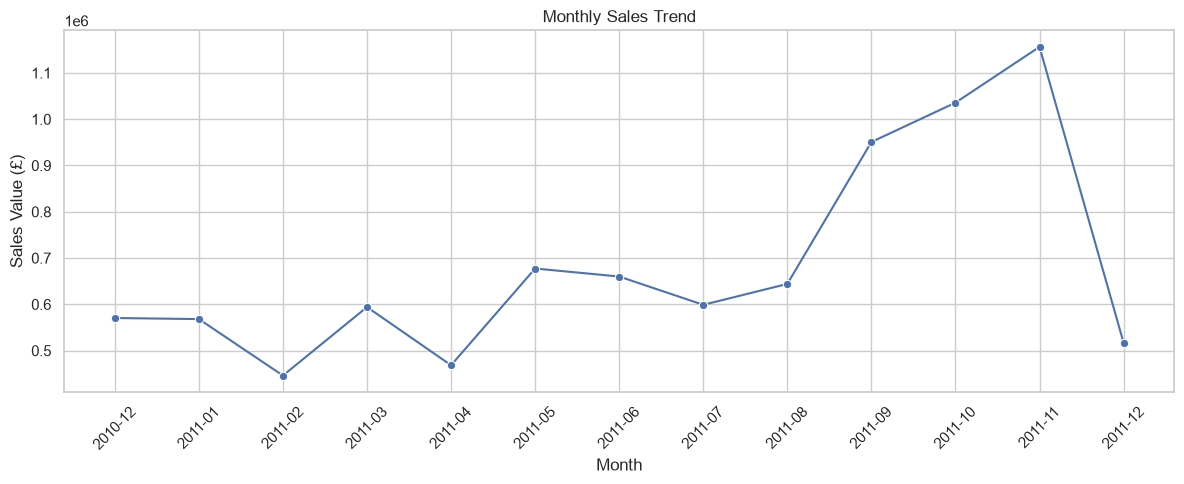

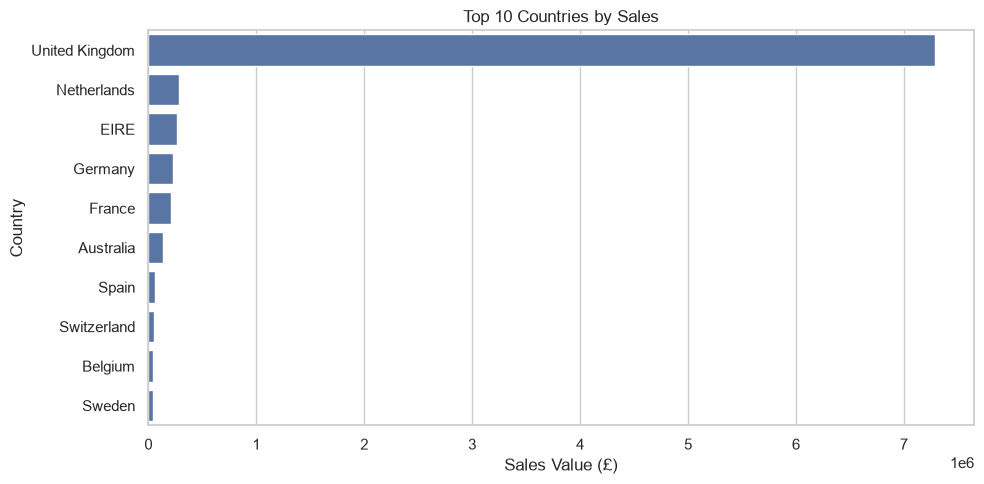

In [12]:

# Basic business statistics
print("Total Customers:", df_clean["CustomerID"].nunique())
print("Total Invoices:", df_clean["InvoiceNo"].nunique())
print("Total Sales Value:", round(df_clean["TotalAmount"].sum(), 2))
print("Average Transaction Line Value:", round(df_clean["TotalAmount"].mean(), 2))
print("Average Quantity per Line:", round(df_clean["Quantity"].mean(), 2))

# Monthly sales trend
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

monthly_sales = (
    df_clean.groupby("Month")["TotalAmount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x="Month", y="TotalAmount", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Value (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Top 10 countries by sales
country_sales = (
    df_clean.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(data=country_sales, x="TotalAmount", y="Country")
plt.title("Top 10 Countries by Sales")
plt.xlabel("Sales Value (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


In [13]:

# Reference date: one day after the last transaction
reference_date = df_clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = df_clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

rfm["Recency"] = (
    reference_date - rfm["LastPurchase"].dt.normalize()
).dt.days

# Keep required RFM columns
rfm = rfm[["CustomerID", "Recency", "Frequency", "Monetary"]]

print("Reference Date:", reference_date.date())
print("Total Customers:", len(rfm))

display(rfm.head(10))

print("\nRFM Statistical Summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))


Reference Date: 2011-12-10
Total Customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40
5,12352,37,8,2506.04
6,12353,205,1,89.00
7,12354,233,1,1079.40
8,12355,215,1,459.40
9,12356,23,3,2811.43



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.75,5.00,1660.60
max,374.00,209.00,280206.02


RFM features scaled successfully!
Scaled data shape: (4338, 3)


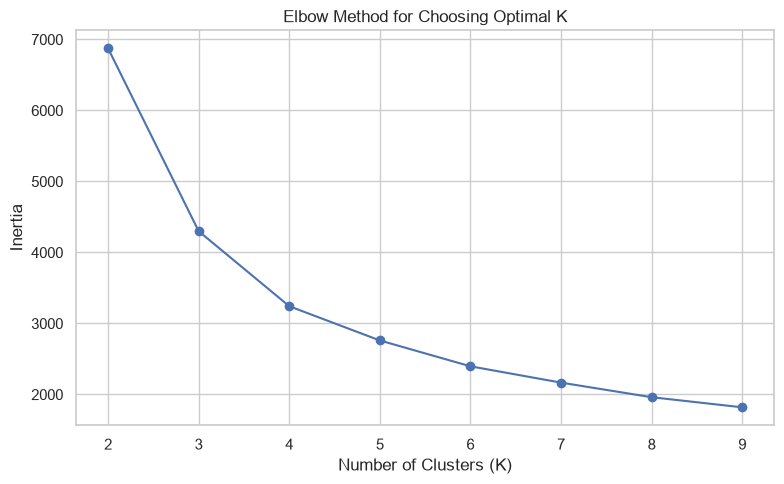

In [14]:

# Select RFM features
X = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce the effect of extreme values
X_log = X.copy()
X_log["Frequency"] = np.log1p(X_log["Frequency"])
X_log["Monetary"] = np.log1p(X_log["Monetary"])

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("RFM features scaled successfully!")
print("Scaled data shape:", X_scaled.shape)

# Elbow Method
inertias = []
k_values = range(2, 10)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method for Choosing Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig("outputs/elbow_method_notebook.png", dpi=150)
plt.show()


In [17]:

print("RFM columns:", rfm.columns.tolist())
print("RFM shape:", rfm.shape)


RFM columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary']
RFM shape: (4338, 4)


In [18]:

# Re-create customer clusters
X = rfm[["Recency", "Frequency", "Monetary"]].copy()

X_log = X.copy()
X_log["Frequency"] = np.log1p(X_log["Frequency"])
X_log["Monetary"] = np.log1p(X_log["Monetary"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster column created successfully!")
display(rfm.head())
print(rfm["Cluster"].value_counts().sort_index())


Cluster column created successfully!


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,3,7,4310.00,1
2,12348,76,4,1797.24,3
3,12349,19,1,1757.55,3
4,12350,311,1,334.40,2


Cluster
0    1377
1     573
2     938
3    1450
Name: count, dtype: int64


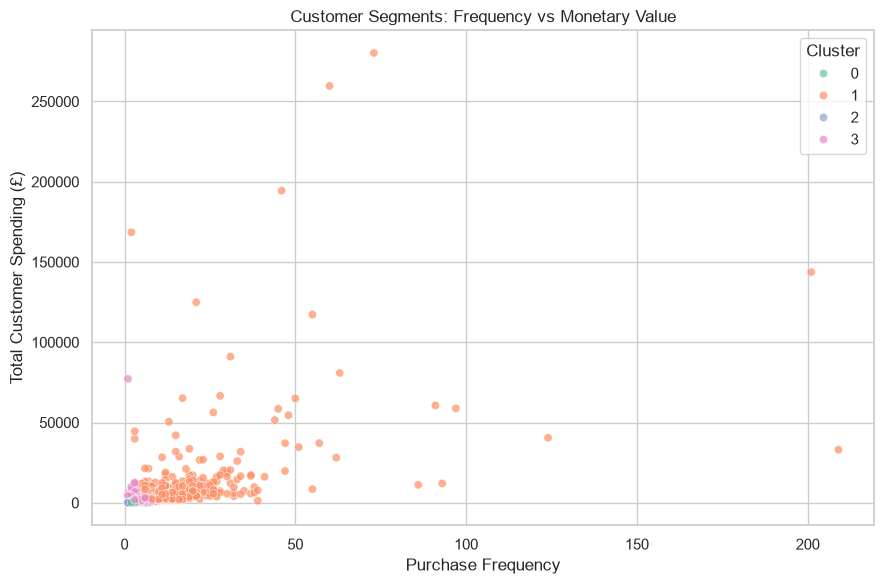

In [19]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segments: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Customer Spending (£)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig("outputs/frequency_monetary_notebook.png", dpi=150)
plt.show()


In [20]:

# Assign business-friendly names based on cluster profiles
segment_names = {
    0: "Occasional Customers",
    1: "High-Value Loyal Customers",
    2: "At-Risk / Inactive Customers",
    3: "Regular Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print("Customer Segments:")
display(
    rfm.groupby("Segment").agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    ).round(2).sort_values("Avg_Monetary", ascending=False)
)


Customer Segments:


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,
High-Value Loyal Customers,573,20.32,15.81,9799.78
Regular Customers,1450,46.58,4.21,1642.33
At-Risk / Inactive Customers,938,259.92,1.37,385.39
Occasional Customers,1377,58.60,1.51,384.22


In [21]:

recommendations = pd.DataFrame({
    "Customer Segment": [
        "High-Value Loyal Customers",
        "Regular Customers",
        "Occasional Customers",
        "At-Risk / Inactive Customers"
    ],
    "Business Recommendation": [
        "Offer loyalty rewards, VIP benefits and early access to new products.",
        "Use personalized recommendations and repeat-purchase offers.",
        "Send targeted promotions to encourage more frequent purchases.",
        "Run re-engagement campaigns with relevant offers and reminders."
    ]
})

display(recommendations)
recommendations.to_csv("outputs/business_recommendations.csv", index=False)

print("Business recommendations saved successfully!")


,Customer Segment,Business Recommendation
0,High-Value Loyal Customers,"Offer loyalty rewards, VIP benefits and early ..."
1,Regular Customers,Use personalized recommendations and repeat-pu...
2,Occasional Customers,Send targeted promotions to encourage more fre...
3,At-Risk / Inactive Customers,Run re-engagement campaigns with relevant offe...


Business recommendations saved successfully!


In [22]:

print("=" * 55)
print("CUSTOMER SEGMENTATION - FINAL RESULTS")
print("=" * 55)

print("Dataset: UCI Online Retail")
print("Customers Analysed:", rfm["CustomerID"].nunique())
print("Number of Clusters:", rfm["Cluster"].nunique())
print("Total Sales Value (£):", round(df_clean["TotalAmount"].sum(), 2))
print("Average Customer Monetary Value (£):", round(rfm["Monetary"].mean(), 2))

print("\nCustomer Count by Segment:")
display(
    rfm.groupby("Segment").size()
       .reset_index(name="Number of Customers")
       .sort_values("Number of Customers", ascending=False)
)

print("\nHighest Average Spending Segment:")
display(
    rfm.groupby("Segment")["Monetary"]
       .mean()
       .sort_values(ascending=False)
       .head(1)
       .round(2)
)


CUSTOMER SEGMENTATION - FINAL RESULTS
Dataset: UCI Online Retail
Customers Analysed: 4338
Number of Clusters: 4
Total Sales Value (£): 8887208.89
Average Customer Monetary Value (£): 2048.69

Customer Count by Segment:


,Segment,Number of Customers
3,Regular Customers,1450
2,Occasional Customers,1377
0,At-Risk / Inactive Customers,938
1,High-Value Loyal Customers,573



Highest Average Spending Segment:


Segment
High-Value Loyal Customers    9799.78
Name: Monetary, dtype: float64

In [23]:

display(Markdown("""
## Conclusion

Customer segmentation was performed on the UCI Online Retail dataset using
Recency, Frequency and Monetary (RFM) features and K-Means clustering.

The analysis grouped customers into four segments based on their purchasing
behaviour. High-value customers can be targeted with loyalty benefits, regular
customers with personalized offers, occasional customers with repeat-purchase
campaigns, and inactive customers with re-engagement offers.

This segmentation can help businesses plan targeted marketing campaigns,
improve customer retention and allocate marketing resources more effectively.

**Limitation:** The segments depend on the selected features, preprocessing
steps and number of clusters. The recommendations should be validated using
actual campaign results before business implementation.
"""))



## Conclusion

Customer segmentation was performed on the UCI Online Retail dataset using
Recency, Frequency and Monetary (RFM) features and K-Means clustering.

The analysis grouped customers into four segments based on their purchasing
behaviour. High-value customers can be targeted with loyalty benefits, regular
customers with personalized offers, occasional customers with repeat-purchase
campaigns, and inactive customers with re-engagement offers.

This segmentation can help businesses plan targeted marketing campaigns,
improve customer retention and allocate marketing resources more effectively.

**Limitation:** The segments depend on the selected features, preprocessing
steps and number of clusters. The recommendations should be validated using
actual campaign results before business implementation.


In [24]:
cd ~/Desktop/OIBSIP/DataAnalytics-L1-CustomerSegmentation

/Users/mackbookpro/Desktop/OIBSIP/DataAnalytics-L1-CustomerSegmentation


In [25]:
ls

clustering_analysis.py
Customer_Segmentation_Analysis.ipynb.ipynb
data/
inspect_clean_data.py
outputs/
rfm_analysis.py
